In [13]:
import pandas as pd
import numpy as np
import tensorflow as tf

In [14]:
x = np.array([0.2,1.2,1,1.4,-1.5,0.5,-0.5])
y = np.array([5.6,8.6,8,9.2,0.5,6.5,3.5])
eta = 0.2
initial_w, initial_b = 0.3,0.1

In [15]:
class Model(tf.Module):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.w = tf.Variable(initial_w)
        self.b = tf.Variable(initial_b)
    
    def __call__(self, x):
        return self.w * x + self.b # To calculate the weighted sum of 
model = Model()

#### Loss funtion to calculate the loss

In [16]:
def loss(predicted_y, actual_y):
    return tf.reduce_mean(tf.square(predicted_y - actual_y))

##### conversion of np.array → 0 D Tensors

In [36]:
x = tf.convert_to_tensor(x, dtype=tf.float32)
y = tf.convert_to_tensor(y, dtype=tf.float32)



### Initial Weights

In [18]:
model.w.numpy(), model.b.numpy()

(np.float32(0.3), np.float32(0.1))

### function to train the model

In [19]:
def train(model, inputs, outputs, learning_rate):
    with tf.GradientTape() as t:
        current_loss = loss(model(inputs), outputs)
    dw, db = t.gradient(current_loss, [model.w, model.b])
    model.w.assign_sub(learning_rate * dw)
    model.b.assign_sub(learning_rate * db)
    return current_loss

In [29]:
model = Model()
list_w, list_b, losses = [],[],[]
for epoch in range(20):
    list_w.append(model.w.numpy())
    list_b.append(model.b.numpy())
    current_loss = train(model,x,y,learning_rate=0.1)
    losses.append(current_loss)
    print(f"Loss = {current_loss.numpy()}, w = {model.w.numpy()}, b = {model.b.numpy()}")

Loss = 40.191871643066406, w = 1.1766571998596191, b = 1.2574286460876465
Loss = 21.90599250793457, w = 1.7971644401550293, b = 2.125762701034546
Loss = 12.019221305847168, w = 2.233139753341675, b = 2.779653549194336
Loss = 6.652888774871826, w = 2.536583185195923, b = 3.2741165161132812
Loss = 3.7248435020446777, w = 2.7451975345611572, b = 3.6497464179992676
Loss = 2.115959882736206, w = 2.8862721920013428, b = 3.9365413188934326
Loss = 1.2237073183059692, w = 2.9795196056365967, b = 4.156706809997559
Loss = 0.7229235768318176, w = 3.0391433238983154, b = 4.326711177825928
Loss = 0.4375726878643036, w = 3.0753469467163086, b = 4.458796501159668
Loss = 0.27193549275398254, w = 3.095433235168457, b = 4.5620856285095215
Loss = 0.17366066575050354, w = 3.1046056747436523, b = 4.643397331237793
Loss = 0.11389163881540298, w = 3.106550693511963, b = 4.707843780517578
Loss = 0.07655998319387436, w = 3.103860855102539, b = 4.759273052215576
Loss = 0.05259937793016434, w = 3.098344087600708,

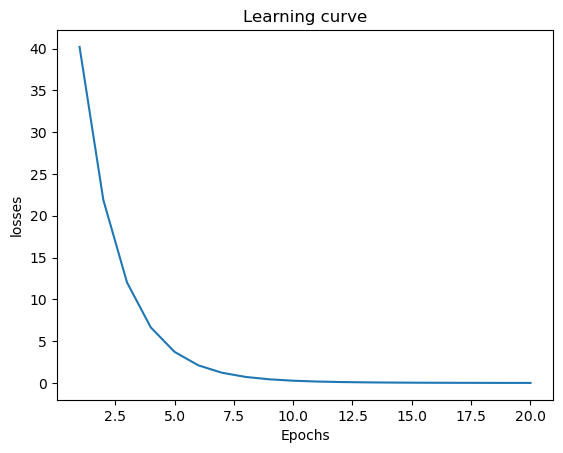

In [30]:
import matplotlib.pyplot as plt
# lets plot a learning curve 
# Elbow Method → 
plt.plot(range(1,21), losses)
plt.xlabel("Epochs")
plt.ylabel("losses")
plt.title("Learning curve")
plt.show()

### Using Keras API

In [40]:
initializer_w = tf.keras.initializers.Constant(value=0.3)
initializer_b = tf.keras.initializers.Constant(value=0.1)
model = tf.keras.Sequential([tf.keras.Input(shape=(1,)),
                             tf.keras.layers.Dense(1, kernel_initializer= initializer_w,
                                                   bias_initializer = initializer_b)])
model.compile(optimizer = tf.keras.optimizers.SGD(learning_rate=0.1),
              loss = 'mean_squared_error')
history = model.fit(x,y,epochs= 20)

Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step - loss: 40.1919
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 21.9060
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 12.0192
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 6.6529
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 3.7248
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 2.1160
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 1.2237
Epoch 8/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.7229
Epoch 9/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 0.4376
Epoch 10/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.2719
Epoch 11/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.1737
Epoch 12/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - loss: 0.1139
Epoch 13/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.0766
Epoch 14/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.0526
Epoch 15/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 0.0368
Epoch 16/20
1/1 ━━━━━━━━━━━━━━

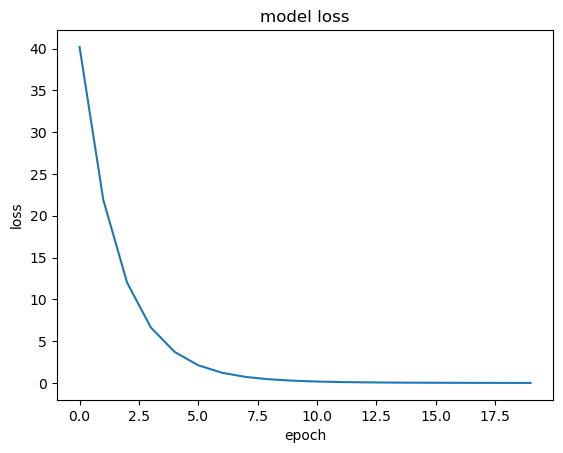

In [41]:
plt.plot(history.history['loss'])
plt.title("model loss")
plt.ylabel('loss')
plt.xlabel('epoch')
plt.show()